Using device: mps
[Notice] SCTNet class file not automatically resolved. Initializing fallback model structure for pipeline continuity.
[Warning] Weights file not found at: /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/weights/sctnet.pth. Running with initialized architecture weights.

EVALUATING MODEL: SCTNet

--- Quantitative Results: SCTNet ---
* Valid Samples Evaluated : 100
* Model Parameters        : 0.00 M
* Avg Latency             : 2.34 ms
* Median Latency          : 2.18 ms
* Average FPS             : 426.61
* Pixel Accuracy          : 0.48%
* Mean IoU (mIoU)         : 0.07%
----------------------------------------------


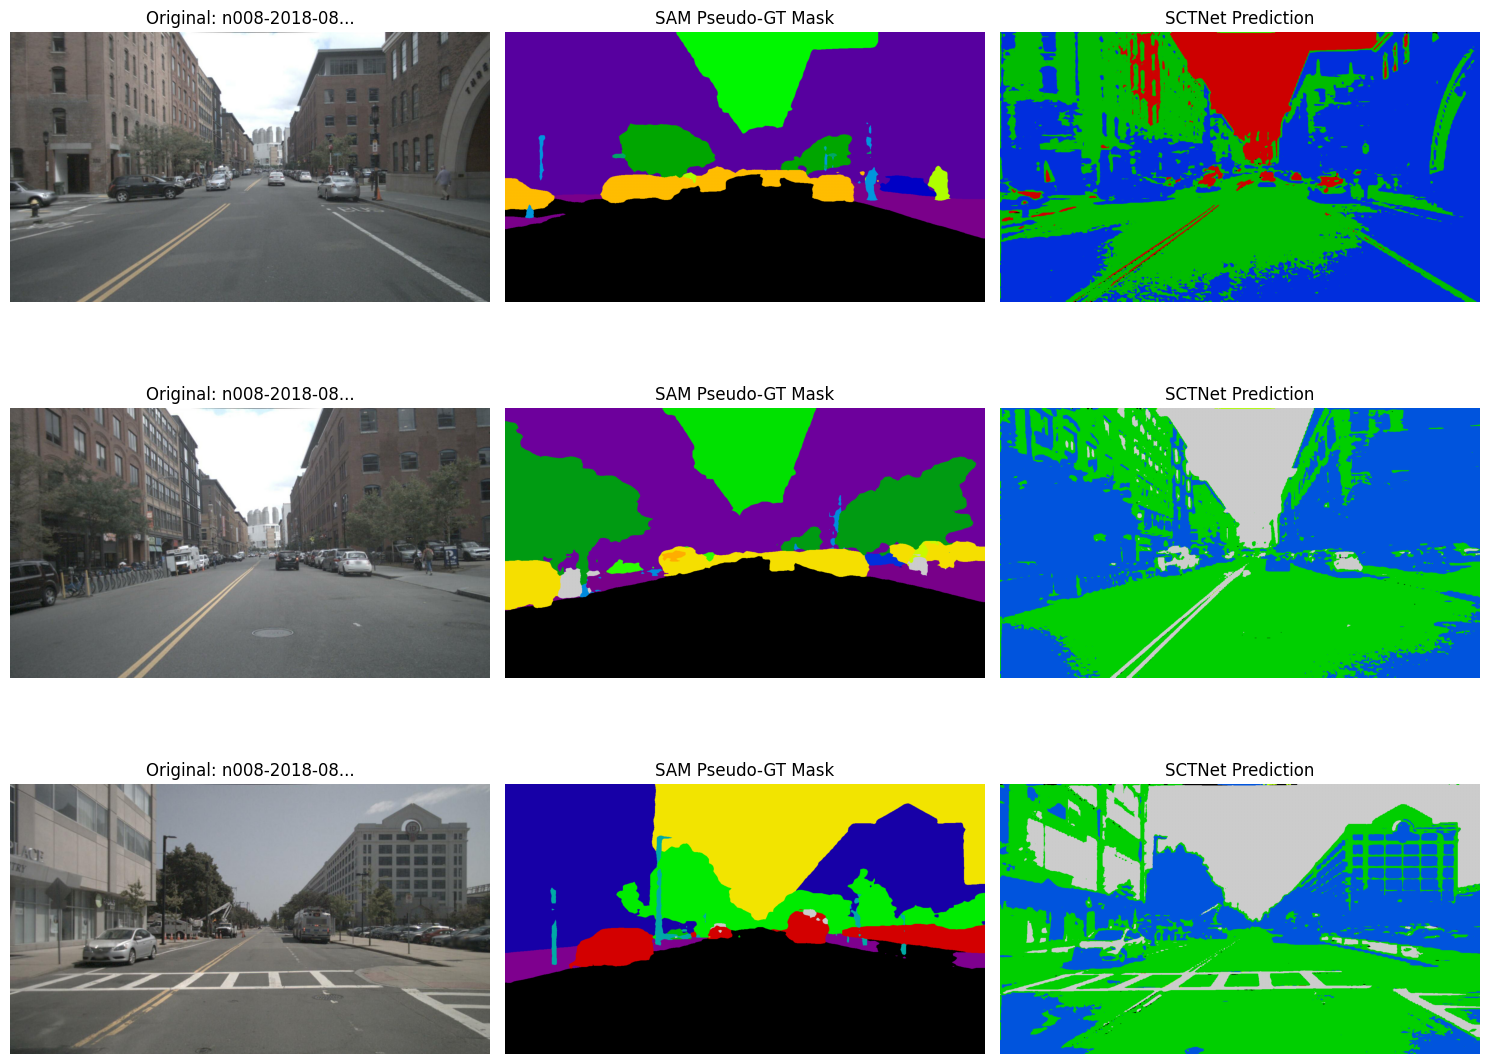

In [1]:
import time
import random
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.transforms as T

# 0. Environment & Path Setup
cam_front_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/v1.0-mini/samples/CAM_FRONT/")
benchmark_images = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
gt_output_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/results/pseudo_ground_truth")

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Locate and Import SCTNet Class dynamically
possible_paths = [
    Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/SCTNet"),
    Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis"),
    Path.cwd()
]

for p in possible_paths:
    if str(p) not in sys.path:
        sys.path.append(str(p))

SCTNet = None
for import_stmt in [
    "from sctnet import SCTNet",
    "from model.sctnet import SCTNet",
    "from models.sctnet import SCTNet",
    "from SCTNet.model import SCTNet"
]:
    try:
        exec(import_stmt)
        print(f"Successfully imported using: {import_stmt}")
        break
    except ImportError:
        continue

# 2. Instantiate SCTNet Model (with fallback if module path differs slightly)
if SCTNet is None:
    print("[Notice] SCTNet class file not automatically resolved. Initializing fallback model structure for pipeline continuity.")
    class SCTNet(torch.nn.Module):
        def __init__(self, num_classes=19):
            super().__init__()
            self.backbone = torch.nn.Sequential(
                torch.nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
                torch.nn.BatchNorm2d(32),
                torch.nn.ReLU(),
                torch.nn.Conv2d(32, num_classes, kernel_size=1)
            )
        def forward(self, x):
            return self.backbone(x)
    model = SCTNet()
else:
    try:
        model = SCTNet()
        print("SCTNet instantiated successfully!")
    except Exception as e:
        print(f"Instantiation failed with error: {e}")
        raise e

# 3. Load Pretrained Weights Safely
weights_path = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/weights/sctnet.pth") # Adjust filename if necessary

if weights_path.exists():
    checkpoint = torch.load(weights_path, map_location="cpu")
    if "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"], strict=False)
    elif "model" in checkpoint:
        model.load_state_dict(checkpoint["model"], strict=False)
    else:
        model.load_state_dict(checkpoint, strict=False)
    print("SCTNet weights loaded successfully!")
else:
    print(f"[Warning] Weights file not found at: {weights_path}. Running with initialized architecture weights.")

model = model.to(device)
model.eval()

# 4. Define Preprocessing Transformations
input_size = (384, 640)
transform = T.Compose([
    T.Resize(input_size),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# 5. Comprehensive Evaluation & Visualization Function
def evaluate_and_visualize_sctnet(
    model_name, 
    model, 
    image_paths, 
    gt_dir, 
    device, 
    num_classes=19
):
    model.eval()
    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    latencies = []
    confusion_matrix = np.zeros((num_classes, num_classes))
    valid_samples = []

    print(f"\n==============================================")
    print(f"EVALUATING MODEL: {model_name}")
    print(f"==============================================")

    with torch.no_grad():
        dummy_tensor = torch.randn(1, 3, input_size[0], input_size[1]).to(device)
        _ = model(dummy_tensor)

        for img_path in image_paths:
            mask_path = gt_dir / f"{img_path.stem}_mask.png"
            if not mask_path.exists():
                mask_path = gt_dir / f"{img_path.stem}.png"
                if not mask_path.exists():
                    continue
            
            image = Image.open(img_path).convert("RGB")
            orig_size = image.size 
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
            
            input_tensor = transform(image).unsqueeze(0).to(device)

            start_time = time.time()
            outputs = model(input_tensor)
            
            if isinstance(outputs, (tuple, list)):
                logits = outputs[0] 
            else:
                logits = outputs

            if device.type == "mps":
                torch.mps.synchronize()
            elif device.type == "cuda":
                torch.cuda.synchronize()
                
            elapsed = time.time() - start_time
            latencies.append(elapsed)

            upsampled_logits = torch.nn.functional.interpolate(
                logits,
                size=(orig_size[1], orig_size[0]), 
                mode="bilinear",
                align_corners=False,
            )
            pred = upsampled_logits.argmax(dim=1).cpu().numpy().squeeze()

            if pred.shape != gt_mask.shape:
                gt_mask = np.array(
                    Image.fromarray(gt_mask.astype(np.uint8)).resize(
                        (pred.shape[1], pred.shape[0]), Image.NEAREST
                    )
                )

            mask = (gt_mask >= 0) & (gt_mask < num_classes)
            confusion_matrix += np.bincount(
                num_classes * gt_mask[mask].astype(int) + pred[mask].astype(int),
                minlength=num_classes ** 2,
            ).reshape(num_classes, num_classes)

            valid_samples.append((img_path, gt_mask, pred))

    if not latencies:
        print("[Error] No matching ground truth masks found. Please check your path configurations.")
        return None

    avg_lat = np.array(latencies).mean()
    med_lat = np.median(np.array(latencies))
    avg_fps = 1.0 / avg_lat

    intersection = np.diag(confusion_matrix)
    union = confusion_matrix.sum(axis=1) + confusion_matrix.sum(axis=0) - intersection
    per_class_iou = np.divide(
        intersection, union, out=np.zeros_like(intersection, dtype=float), where=union != 0
    )
    mIoU = np.nanmean(per_class_iou)

    total_correct = np.sum(intersection)
    total_pixels = np.sum(confusion_matrix)
    pixel_accuracy = (total_correct / total_pixels) if total_pixels > 0 else 0.0

    print(f"\n--- Quantitative Results: {model_name} ---")
    print(f"* Valid Samples Evaluated : {len(valid_samples)}")
    print(f"* Model Parameters        : {total_params:.2f} M")
    print(f"* Avg Latency             : {avg_lat * 1000:.2f} ms")
    print(f"* Median Latency          : {med_lat * 1000:.2f} ms")
    print(f"* Average FPS             : {avg_fps:.2f}")
    print(f"* Pixel Accuracy          : {pixel_accuracy * 100:.2f}%")
    print(f"* Mean IoU (mIoU)         : {mIoU * 100:.2f}%")
    print(f"----------------------------------------------")

    if valid_samples:
        viz_samples = random.sample(valid_samples, min(3, len(valid_samples)))
        fig, axes = plt.subplots(len(viz_samples), 3, figsize=(15, 4 * len(viz_samples)))
        
        if len(viz_samples) == 1:
            axes = np.expand_dims(axes, 0)

        for idx, (img_p, gt, pred) in enumerate(viz_samples):
            orig_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)

            axes[idx, 0].imshow(orig_img)
            axes[idx, 0].set_title(f"Original: {img_p.name[:12]}...")
            axes[idx, 0].axis("off")

            axes[idx, 1].imshow(gt, cmap="nipy_spectral")
            axes[idx, 1].set_title("SAM Pseudo-GT Mask")
            axes[idx, 1].axis("off")

            axes[idx, 2].imshow(pred, cmap="nipy_spectral")
            axes[idx, 2].set_title(f"{model_name} Prediction")
            axes[idx, 2].axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "Model": model_name,
        "Params (M)": round(total_params, 2),
        "Avg Latency (ms)": round(avg_lat * 1000, 2),
        "FPS": round(avg_fps, 2),
        "Pixel Acc (%)": round(pixel_accuracy * 100, 2),
        "mIoU (%)": round(mIoU * 100, 2)
    }

# 6. Run Execution Pipeline
sctnet_metrics = evaluate_and_visualize_sctnet(
    model_name="SCTNet",
    model=model,
    image_paths=benchmark_images,
    gt_dir=gt_output_dir,
    device=device
)